# Часть 1 Бустинг (5 баллов)

В этой части будем предсказывать зарплату data scientist-ов в зависимости  от ряда факторов с помощью градиентного бустинга.

В датасете есть следующие признаки:



* work_year: The number of years of work experience in the field of data science.

* experience_level: The level of experience, such as Junior, Senior, or Lead.

* employment_type: The type of employment, such as Full-time or Contract.

* job_title: The specific job title or role, such as Data Analyst or Data Scientist.

* salary: The salary amount for the given job.

* salary_currency: The currency in which the salary is denoted.

* salary_in_usd: The equivalent salary amount converted to US dollars (USD) for comparison purposes.

* employee_residence: The country or region where the employee resides.

* remote_ratio: The percentage of remote work offered in the job.

* company_location: The location of the company or organization.

* company_size: The company's size is categorized as Small, Medium, or Large.

In [ ]:
import pandas as pd
import numpy as np

In [ ]:
import time
df = pd.read_csv("ds_salaries.csv")
df.head()

,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2023,SE,FT,Principal Data Scientist,80000,EUR,85847,ES,100,ES,L
1,2023,MI,CT,ML Engineer,30000,USD,30000,US,100,US,S
2,2023,MI,CT,ML Engineer,25500,USD,25500,US,100,US,S
3,2023,SE,FT,Data Scientist,175000,USD,175000,CA,100,CA,M
4,2023,SE,FT,Data Scientist,120000,USD,120000,CA,100,CA,M


In [ ]:
df.shape

(3755, 11)

## Задание 1 (0.5 балла) Подготовка



*   Разделите выборку на train, val, test (80%, 10%, 10%)
*   Выдерите salary_in_usd в качестве таргета
*   Найдите и удалите признак, из-за которого возможен лик в данных


In [ ]:
categorical_features = ['experience_level', 'employment_type', 'job_title', 'salary_currency', 'employee_residence', 'company_location', 'company_size']
df_clean = pd.get_dummies(df, columns=categorical_features , dtype=int)

In [ ]:
from sklearn.model_selection import train_test_split

y = df_clean['salary_in_usd']
X = df_clean.drop('salary_in_usd', axis = 1).drop('salary', axis = 1)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.1, random_state = 52)
X_train_train, X_train_val, y_train_train, y_train_val = train_test_split(X_train, y_train, test_size = 0.11, random_state = 52)

In [ ]:
print(len(y_test)/len(X))

0.10013315579227697


## Задание 2 (0.5 балла) Линейная модель


*   Закодируйте категориальные  признаки с помощью OneHotEncoder
*   Обучите модель линейной регрессии
*   Оцените  качество через MAPE и RMSE


In [ ]:
from scipy.sparse import hstack
from sklearn.compose import ColumnTransformer

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_percentage_error, mean_squared_error
from sklearn.preprocessing import OneHotEncoder

linreg = LinearRegression()
linreg.fit(X_train_train, y_train_train)

#Для валидации
prediction_train_train = linreg.predict(X_train_train)
mse_train_train = mean_squared_error(y_train_train, prediction_train_train)
rmse_train_train = np.sqrt(mse_train_train)
mape_train_train = mean_absolute_percentage_error(y_train_train, prediction_train_train)

#Для теста
prediction_test = linreg.predict(X_test)
mse_test = mean_squared_error(y_test, prediction_test)
rmse_test = np.sqrt(mse_test)
mape_test = mean_absolute_percentage_error(y_test, prediction_test)

print(f'MAPE на трейне: {np.round(mape_train_train*100, 2)}%')
print(f'RMSE на трейне: {rmse_train_train}')
print('-'*40)
print(f'MAPE на тесте: {np.round(mape_test*100, 2)}%')
print(f'RMSE на тесте: {rmse_test}')

MAPE на трейне: 30.98%
RMSE на трейне: 44915.71317240196
----------------------------------------
MAPE на тесте: 35.36%
RMSE на тесте: 51918.437265359054


## Задание 3 (0.5 балла) XGboost

Начнем с библиотеки xgboost.

Обучите модель `XGBRegressor` на тех же данных, что линейную модель, подобрав оптимальные гиперпараметры (`max_depth, learning_rate, n_estimators, gamma`, etc.) по валидационной выборке. Оцените качество итоговой модели (MAPE, RMSE), скорость обучения и скорость предсказания.

In [ ]:
from xgboost.sklearn import XGBRegressor

params = {
    'max_depth' : 7 ,
    'learning_rate' : 0.2,
    'n_estimators' : 250 ,
    'gamma' : 0.1
}

mape_best = None
best_paramms = {}

for depth in [5, 7, 9]:
    for lr in [0.05, 0.1, 0.2]:
        for iteration in [100, 200, 400]:
            paramems = {
                'max_depth' : depth ,
                'learning_rate' : lr ,
                'n_estimators' : iteration,
                'gamma' : 0.1}
            model_XGb = XGBRegressor(**paramems)
            model_XGb.fit(X_train_train, y_train_train)

            prediction_cat_train = model_XGb.predict(X_train_val)
            mape_cat_train = mean_absolute_percentage_error(y_train_val, prediction_cat_train)
            if mape_best is None or mape_best > mape_cat_train:
                mape_best = mape_cat_train
                best_paramms = {
                    'max_depth' : depth ,
                    'learning_rate' : lr ,
                    'n_estimators' : iteration,
                    'gamma' : 0.1}

XGboost = XGBRegressor(**best_paramms, random_state=42)
XGboost.fit(X_train_train, y_train_train)

#На трейне
prediction_XGb_train = XGboost.predict(X_train_train)
mse_XGb_train = mean_squared_error(y_train_train, prediction_XGb_train)
rmse_XGb_train = np.sqrt(mse_XGb_train)
mape_XGb_train = mean_absolute_percentage_error(y_train_train, prediction_XGb_train)

#На валидации
prediction_XGb_val = XGboost.predict(X_train_val)
mse_XGb_val = mean_squared_error(y_train_val, prediction_XGb_val)
rmse_XGb_val = np.sqrt(mse_XGb_val)
mape_XGb_val = mean_absolute_percentage_error(y_train_val, prediction_XGb_val)

#На тесте
prediction_XGb_test = XGboost.predict(X_test)
mse_XGb_test = mean_squared_error(y_test, prediction_XGb_test)
rmse_XGb_test = np.sqrt(mse_XGb_test)
mape_XGb_test = mean_absolute_percentage_error(y_test, prediction_XGb_test)

print(f'MAPE на трейне: {np.round(mape_XGb_train*100, 2)}%')
print(f'RMSE на трейне: {np.round(rmse_XGb_train, 2)}')
print('-'*40)
print(f'MAPE на валидации: {np.round(mape_XGb_val*100, 2)}%')
print(f'RMSE на валидации: {np.round(rmse_XGb_val, 2)}')
print('-'*40)
print(f'MAPE на тесте: {np.round(mape_XGb_test*100, 2)}%')
print(f'RMSE на тесте: {np.round(rmse_XGb_test, 2)}')

MAPE на трейне: 25.11%
RMSE на трейне: 40682.12
----------------------------------------
MAPE на валидации: 29.2%
RMSE на валидации: 42653.04
----------------------------------------
MAPE на тесте: 33.67%
RMSE на тесте: 51950.66


In [ ]:
best_paramms

{'max_depth': 7, 'learning_rate': 0.2, 'n_estimators': 200, 'gamma': 0.1}

## Задание 4 (1 балл) CatBoost

Теперь библиотека CatBoost.

Обучите модель `CatBoostRegressor`, подобрав оптимальные гиперпараметры (`depth, learning_rate, iterations`, etc.) по валидационной выборке. Оцените качество итоговой модели (MAPE, RMSE), скорость обучения и скорость предсказания.

In [ ]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 9.3 MB/s eta 0:00:00


In [ ]:
from catboost import CatBoostRegressor

params = {
    'depth' : 7 ,
    'learning_rate' : 0.09 ,
    'iterations' : 400
}
mape_best = None
best_paramms = {}

for depth in [5, 7, 9]:
    for lr in [0.05, 0.1, 0.2]:
        for iteration in [100, 200, 400]:
            paramems = {
                'depth' : depth ,
                'learning_rate' : lr ,
                'iterations' : iteration}
            model_catb = CatBoostRegressor(**paramems, verbose=False)
            model_catb.fit(X_train_train, y_train_train)

            prediction_cat_train = model_catb.predict(X_train_val)
            mape_cat_train = mean_absolute_percentage_error(y_train_val, prediction_cat_train)
            if mape_best is None or mape_best > mape_cat_train:
                mape_best = mape_cat_train
                best_paramms = {
                    'depth' : depth ,
                    'learning_rate' : lr ,
                    'iterations' : iteration}

catboost_model = CatBoostRegressor(**best_paramms, verbose=False)
catboost_model.fit(X_train_train, y_train_train)

#На трейне
prediction_XGb_train = catboost_model.predict(X_train_train)
mse_XGb_train = mean_squared_error(y_train_train, prediction_XGb_train)
rmse_XGb_train = np.sqrt(mse_XGb_train)
mape_XGb_train = mean_absolute_percentage_error(y_train_train, prediction_XGb_train)

#На валидации
prediction_XGb_val = catboost_model.predict(X_train_val)
mse_XGb_val = mean_squared_error(y_train_val, prediction_XGb_val)
rmse_XGb_val = np.sqrt(mse_XGb_val)
mape_XGb_val = mean_absolute_percentage_error(y_train_val, prediction_XGb_val)

#На тесте
prediction_XGb_test = catboost_model.predict(X_test)
mse_XGb_test = mean_squared_error(y_test, prediction_XGb_test)
rmse_XGb_test = np.sqrt(mse_XGb_test)
mape_XGb_test = mean_absolute_percentage_error(y_test, prediction_XGb_test)

print(f'MAPE на трейне: {np.round(mape_XGb_train*100, 2)}%')
print(f'RMSE на трейне: {np.round(rmse_XGb_train, 2)}')
print('-'*40)
print(f'MAPE на валидации: {np.round(mape_XGb_val*100, 2)}%')
print(f'RMSE на валидации: {np.round(rmse_XGb_val, 2)}')
print('-'*40)
print(f'MAPE на тесте: {np.round(mape_XGb_test*100, 2)}%')
print(f'RMSE на тесте: {np.round(rmse_XGb_test, 2)}')

MAPE на трейне: 28.45%
RMSE на трейне: 41906.38
----------------------------------------
MAPE на валидации: 30.01%
RMSE на валидации: 42525.44
----------------------------------------
MAPE на тесте: 32.31%
RMSE на тесте: 51138.5


In [ ]:
best_paramms

{'depth': 5, 'learning_rate': 0.2, 'iterations': 400}

По сравнению с XGboost показатели на трейне и на тесте выровнялись, значит переобученность снизилась, это хорошо

Для применения catboost моделей не обязательно сначала кодировать категориальные признаки, модель может кодировать их сама. Обучите catboost с подбором оптимальных гиперпараметров снова, используя pool для передачи данных в модель с указанием какие признаки категориальные, а какие нет с помощью параметра cat_features. Оцените качество и время. Стало ли лучше?

In [ ]:
y_df = df['salary_in_usd']
X_df = df.drop('salary_in_usd', axis = 1).drop('salary', axis = 1)

X_train, X_test_df, y_train, y_test_df = train_test_split(X_df, y_df, test_size = 0.1, random_state = 52)

In [ ]:
from catboost import Pool


#Создаем пулы
pool_train = Pool(data = X_train, label=y_train, cat_features = categorical_features)
pool_test = Pool(data = X_test_df, cat_features = categorical_features)
mape_best = None
best_params = {}

for depth in [5, 7, 9]:
    for lr in [0.05, 0.1, 0.2]:
        for iteration in [100, 200, 400]:
            paramems = {
                'depth' : depth ,
                'learning_rate' : lr ,
                'iterations' : iteration}
            model_cat = CatBoostRegressor(**paramems, verbose=False)
            model_cat.fit(pool_train)

            prediction_cat_train = model_cat.predict(pool_train)
            mape_cat_train = mean_absolute_percentage_error(y_train, prediction_cat_train)
            if mape_best is None or mape_best > mape_cat_train:
                mape_best = mape_cat_train
                best_params = {
                    'depth' : depth ,
                    'learning_rate' : lr ,
                    'iterations' : iteration}


model_catboost = CatBoostRegressor(**best_params, verbose=False)
model_catboost.fit(pool_train)

#На трейне
prediction_cat_train = model_catboost.predict(pool_train)
mse_cat_train = mean_squared_error(y_train, prediction_cat_train)
rmse_cat_train = np.sqrt(mse_cat_train)
mape_cat_train = mean_absolute_percentage_error(y_train, prediction_cat_train)

#На тесте
prediction_cat_test = model_catboost.predict(pool_test)
mse_cat_test = mean_squared_error(y_test, prediction_cat_test)
rmse_cat_test = np.sqrt(mse_cat_test)
mape_cat_test = mean_absolute_percentage_error(y_test, prediction_cat_test)

print(f'MAPE на трейне: {np.round(mape_cat_train*100, 2)}%')
print(f'RMSE на трейне: {np.round(rmse_cat_train, 2)}')
print('-'*40)
print(f'MAPE на тесте: {np.round(mape_cat_test*100, 2)}%')
print(f'RMSE на тесте: {np.round(rmse_cat_test, 2)}')

MAPE на трейне: 32.63%
RMSE на трейне: 44502.1
----------------------------------------
MAPE на тесте: 34.21%
RMSE на тесте: 49822.42


In [ ]:
best_params

{'depth': 9, 'learning_rate': 0.2, 'iterations': 200}

**Ответ:** # -- Проблема переобученности полность ушла, однако само качество незначительно просело по MAPE, по RMSE практически нет изменений на тесте

## Задание 5 (0.5 балла) LightGBM

И наконец библиотека LightGBM - используйте `LGBMRegressor`, снова подберите гиперпараметры, оцените качество и скорость.


In [ ]:
from lightgbm import LGBMRegressor

params = {
    'max_depth' : 7 ,
    'learning_rate' : 0.09 ,
    'n_estimators' : 400
}
mape_best = None
best_paramms = {}

for depth in [5, 7, 9]:
    for lr in [0.05, 0.1, 0.2]:
        for iteration in [100, 200, 400]:
            paramems = {
                'max_depth' : depth ,
                'learning_rate' : lr ,
                'n_estimators' : iteration}
            model_GBM =  LGBMRegressor(**paramems, verbose=-1)
            model_GBM.fit(X_train_train, y_train_train)

            prediction_cat_train = model_GBM.predict(X_train_val)
            mape_cat_train = mean_absolute_percentage_error(y_train_val, prediction_cat_train)
            if mape_best is None or mape_best > mape_cat_train:
                mape_best = mape_cat_train
                best_paramms = {
                    'max_depth' : depth ,
                    'learning_rate' : lr ,
                    'n_estimators' : iteration}

start_time = time.time()
GBM_model =  LGBMRegressor(**best_paramms, verbose=-1)
GBM_model.fit(X_train_train, y_train_train)
fit_time = time.time() - start_time

#На трейне
prediction_XGb_train = GBM_model.predict(X_train_train)
mse_XGb_train = mean_squared_error(y_train_train, prediction_XGb_train)
rmse_XGb_train = np.sqrt(mse_XGb_train)
mape_XGb_train = mean_absolute_percentage_error(y_train_train, prediction_XGb_train)

#На валидации
prediction_XGb_val = GBM_model.predict(X_train_val)
mse_XGb_val = mean_squared_error(y_train_val, prediction_XGb_val)
rmse_XGb_val = np.sqrt(mse_XGb_val)
mape_XGb_val = mean_absolute_percentage_error(y_train_val, prediction_XGb_val)

#На тесте
start_time = time.time()
prediction_XGb_test = GBM_model.predict(X_test)
mse_XGb_test = mean_squared_error(y_test, prediction_XGb_test)
rmse_XGb_test = np.sqrt(mse_XGb_test)
mape_XGb_test = mean_absolute_percentage_error(y_test, prediction_XGb_test)
pred_time = time.time() - start_time


print(f"\nВремя обучения: {fit_time:.2f} сек")
print(f"Время предсказания: {pred_time:.2f} сек")
print('-'*40)
print(f'MAPE на трейне: {np.round(mape_XGb_train*100, 2)}%')
print(f'RMSE на трейне: {np.round(rmse_XGb_train, 2)}')
print('-'*40)
print(f'MAPE на валидации: {np.round(mape_XGb_val*100, 2)}%')
print(f'RMSE на валидации: {np.round(rmse_XGb_val, 2)}')
print('-'*40)
print(f'MAPE на тесте: {np.round(mape_XGb_test*100, 2)}%')
print(f'RMSE на тесте: {np.round(rmse_XGb_test, 2)}')


Время обучения: 0.15 сек
Время предсказания: 0.03 сек
----------------------------------------
MAPE на трейне: 34.21%
RMSE на трейне: 46133.09
----------------------------------------
MAPE на валидации: 32.55%
RMSE на валидации: 43920.6
----------------------------------------
MAPE на тесте: 32.03%
RMSE на тесте: 50255.15


In [ ]:
best_paramms

{'max_depth': 5, 'learning_rate': 0.1, 'n_estimators': 100}

## Задание 6 (2 балла) Сравнение и выводы

Сравните модели бустинга и сделайте про них выводы, какая из моделей показала лучший/худший результат по качеству, скорости обучения и скорости предсказания? Как отличаются гиперпараметры для разных моделей?

**Ответ:** По скорости обучения значительно выделился LightGBM, так же почему-то качество на трене у него хуже чем на тесте, это довольно странно. Нельзя однозначно выделить победителя среди всех моделей, они все отработально +- одинаково. Главное, что мешает выбрать победителя, это вечный компромисс между MAPE и RMSE в рамках каждой модели, к тому же каждая модель по-разному реагирует на перебор гиперпараметров.

# Часть 2 Кластеризация (5 баллов)

Будем работать с данными о том, каких исполнителей слушают пользователи музыкального сервиса.

Каждая строка таблицы - информация об одном пользователе. Каждый столбец - это исполнитель (The Beatles, Radiohead, etc.)

Для каждой пары (пользователь, исполнитель) в таблице стоит число - доля прослушивания этого исполнителя этим пользователем.


In [ ]:
import pandas as pd
ratings = pd.read_excel("https://github.com/evgpat/edu_stepik_rec_sys/blob/main/datasets/sample_matrix.xlsx?raw=true", engine='openpyxl')
ratings.head()

,user,the beatles,radiohead,deathcab for cutie,coldplay,modest mouse,sufjan stevens,dylan. bob,red hot clili peppers,pink fluid,...,municipal waste,townes van zandt,curtis mayfield,jewel,lamb,michal w. smith,群星,agalloch,meshuggah,yellowcard
0,0,NaN,0.020417,NaN,NaN,NaN,NaN,NaN,0.030496,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,NaN,0.184962,0.024561,NaN,NaN,0.136341,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,NaN,NaN,0.028635,NaN,NaN,NaN,0.024559,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4,0.043529,0.086281,0.034590,0.016712,0.015935,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Будем строить кластеризацию исполнителей: если двух исполнителей слушало много людей примерно одинаковую долю своего времени (то есть векторы близки в пространстве), то, возможно исполнители похожи. Эта информация может быть полезна при построении рекомендательных систем.

## Задание 1 (0.5 балла) Подготовка

Транспонируем матрицу ratings, чтобы по строкам стояли исполнители.

In [ ]:
ratings_transpose = ratings.T

Выкиньте строку под названием `user`.

In [ ]:
ratings_transpose = ratings_transpose.drop('user', axis = 0)

In [ ]:
ratings_transpose

,0,1,2,3,4,5,6,7,8,9,...,4990,4991,4992,4993,4994,4995,4996,4997,4998,4999
the beatles,NaN,NaN,NaN,NaN,0.043529,NaN,NaN,NaN,0.093398,0.017621,...,NaN,NaN,0.121169,0.038168,0.007939,0.017884,NaN,0.076923,NaN,NaN
radiohead,0.020417,0.184962,NaN,NaN,0.086281,0.006322,NaN,NaN,NaN,0.019156,...,0.017735,NaN,NaN,NaN,0.011187,NaN,NaN,NaN,NaN,NaN
deathcab for cutie,NaN,0.024561,0.028635,NaN,0.034590,NaN,NaN,NaN,NaN,0.013349,...,0.121344,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.027893
coldplay,NaN,NaN,NaN,NaN,0.016712,NaN,NaN,NaN,NaN,NaN,...,0.217175,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
modest mouse,NaN,NaN,NaN,NaN,0.015935,NaN,NaN,NaN,NaN,0.030437,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
michal w. smith,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
群星,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
agalloch,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
meshuggah,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


В таблице много пропусков, так как пользователи слушают не всех-всех исполнителей, чья музыка представлена в сервисе, а некоторое подмножество (обычно около 30 исполнителей)


Доля исполнителя в музыке, прослушанной  пользователем, равна 0, если пользователь никогда не слушал музыку данного музыканта, поэтому заполните пропуски нулями.



In [ ]:
ratings_transpose.fillna(0, inplace=True)
ratings_transpose.sample()

,0,1,2,3,4,5,6,7,8,9,...,4990,4991,4992,4993,4994,4995,4996,4997,4998,4999
the rolling stones,0.0,0.0,0.024559,0.0,0.0,0.0,0.0,0.0,0.0,0.023829,...,0.0,0.0,0.0,0.0,0.005774,0.0,0.0,0.0,0.0,0.0


## Задание 2 (0.5 балла) Первая кластеризация

Примените KMeans с 5ю кластерами, сохраните полученные лейблы

In [ ]:
from sklearn.cluster import KMeans

In [ ]:
model = KMeans(n_clusters=5, random_state=42)
model.fit(ratings_transpose)

cluster_labels = model.labels_
unique, counts = np.unique(model.labels_, return_counts=True)
for cluster, count in zip(unique, counts):
    print(f"Кластер {cluster}: {count} объектов")

Кластер 0: 115 объектов
Кластер 1: 1 объектов
Кластер 2: 1 объектов
Кластер 3: 882 объектов
Кластер 4: 1 объектов


Выведите размеры кластеров. Полезной ли получилась кластеризация? Почему KMeans может выдать такой результат?

**Ответ:** Кластеризация прошла бесполезно, скорее всего это связано с тем, что кластеров на самом деле намного больше

## Задание 3 (0.5 балла) Объяснение результатов

При кластеризации получилось $\geq 1$ кластера размера 1. Выведите исполнителей, которые составляют такие кластеры. Среди них должна быть группа The Beatles.

In [ ]:
from collections import Counter

sizes = Counter(cluster_labels)

In [ ]:
sizes

Counter({np.int32(4): 1,
         np.int32(0): 115,
         np.int32(2): 1,
         np.int32(3): 882,
         np.int32(1): 1})

In [ ]:
small = []
for cluster, count in sizes.items():
    if count == 1:
        small.append(cluster)

In [ ]:
for cluster in small:
    artist = ratings_transpose.index[cluster == cluster_labels].tolist()
    print(f"Кластер {cluster} группа {artist}")

Кластер 4 группа ['the beatles']
Кластер 2 группа ['niИ']
Кластер 1 группа ['日dir en grey']


Изучите данные, почему именно The Beatles выделяется?

Подсказка: посмотрите на долю пользователей, которые слушают каждого исполнителя, среднюю долю прослушивания.

In [ ]:
top_10_overrated = ratings_transpose.mean(axis=1)
#top_10_overrated_sorted = top_10_overrated.sort_values(ascending=False).head(10)

non_zero_10 = (ratings_transpose > 0).mean(axis = 1)

mean_non_zero_10 = ratings_transpose[ratings_transpose > 0].mean(axis=1)

stats = pd.DataFrame({'Доля прослушиваний': top_10_overrated,
                      'Доля слушающих': non_zero_10,
                      'Средняя доля прослушивания': mean_non_zero_10})
stats_sorted = stats.sort_values('Доля слушающих', ascending=False).head(10)
stats_sorted

,Доля прослушиваний,Доля слушающих,Средняя доля прослушивания
the beatles,0.018369,0.3342,0.054964
radiohead,0.011851,0.2778,0.042661
deathcab for cutie,0.006543,0.1862,0.035141
coldplay,0.006030,0.1682,0.035852
modest mouse,0.005876,0.1628,0.036095
sufjan stevens,0.004969,0.1292,0.038460
dylan. bob,0.004963,0.1262,0.039323
red hot clili peppers,0.003994,0.1258,0.031752
pink fluid,0.004909,0.1256,0.039085
kanye west,0.004641,0.1250,0.037128


**Ответ:** Битлс больше всего слушают, в векторном пространстве точка, отвечающая за битлс, находится на отдалении от остальных

## Задание 4 (0.5 балла) Улучшение кластеризации

Попытаемся избавиться от этой проблемы: нормализуйте данные при помощи `normalize`.

In [ ]:
from sklearn.preprocessing import normalize

ratings_transpose_norm = normalize(ratings_transpose)

Примените KMeans с 5ю кластерами на преобразованной матрице, посмотрите на их размеры. Стало ли лучше? Может ли кластеризация быть полезной теперь?

In [ ]:
modelka = KMeans(n_clusters=5, random_state=42)
modelka.fit(ratings_transpose_norm)

cluster_labels = modelka.labels_
unique, counts = np.unique(modelka.labels_, return_counts=True)
for cluster, count in zip(unique, counts):
    print(f"Кластер {cluster}: {count} объектов")

Кластер 0: 79 объектов
Кластер 1: 162 объектов
Кластер 2: 133 объектов
Кластер 3: 140 объектов
Кластер 4: 486 объектов


**Ответ** # Это уже похоже на потенциально хороший результат

## Задание 5 (1 балл) Центроиды

Выведите для каждого кластера названия топ-10 исполнителей, ближайших к центроиду по косинусной мере. Проинтерпретируйте результат. Что можно сказать о смысле кластеров?

In [ ]:
from scipy.spatial.distance import cosine

centroids = modelka.cluster_centers_

for cluster in range(5):
    print(f"\nКластер {cluster}:")
    distances = []
    for i, artist in enumerate(ratings_transpose_norm):
        dist = cosine(centroids[cluster], artist)
        distances.append((ratings_transpose.index[i], dist))

    distances.sort(key=lambda x: x[1])
    for artist, dist in distances[:10]:
        print(f"  {artist}: {dist:.4f}")


Кластер 0:
  nas: 0.4639
  jay-z: 0.4955
  kanye west: 0.5201
  lupe the gorilla: 0.5839
  a tribe called quest: 0.5867
  the roots featuring d'angelo: 0.5938
  gangstarr: 0.6280
  little brother: 0.6291
  lil' wayne: 0.6326
  murs and 9th wonder: 0.6352

Кластер 1:
  fall out boy: 0.6349
  the all-americian rejects: 0.6560
  paramore: 0.6587
  kelly clarkson: 0.6644
  john mayer: 0.6750
  the fray: 0.6752
  maroon5: 0.6883
  dashboard confesssional: 0.6910
  somethings corporate: 0.7105
  coldplay: 0.7115

Кластер 2:
  brand new: 0.6308
  blink-182: 0.6555
  alkaline trio: 0.6632
  against me!: 0.6656
  underoath: 0.7000
  descendents: 0.7011
  new found glory: 0.7021
  less than jake: 0.7055
  thrice: 0.7062
  chiodos: 0.7124

Кластер 3:
  the beatles: 0.6203
  the rolling stones: 0.6235
  dylan. bob: 0.6565
  who: 0.6982
  led zeppelin.: 0.7075
  miles davis.: 0.7206
  simon and garfunkel: 0.7273
  young, neil: 0.7319
  pink fluid: 0.7320
  velvet underground: 0.7448

Кластер 4:
  

**Ответ:** # -- YOUR ANSWER HERE --

## Задание 6 (1 балл) Визуализация

Хотелось бы как-то визуализировать полученную кластеризацию. Постройте точечные графики `plt.scatter` для нескольких пар признаков исполнителей, покрасив точки в цвета кластеров. Почему визуализации получились такими? Хорошо ли они отражают разделение на кластеры? Почему?

In [ ]:
import matplotlib.pyplot as plt

# -- YOUR CODE HERE --

**Ответ:** # -- YOUR ANSWER HERE --

Для визуализации данных высокой размерности существует метод t-SNE (стохастическое вложение соседей с t-распределением). Данный метод является нелинейным методом снижения размерности: каждый объект высокой размерности будет моделироваться объектов более низкой (например, 2) размерности таким образом, чтобы похожие объекты моделировались близкими, непохожие - далекими с большой вероятностью.

Примените `TSNE` из библиотеки `sklearn` и визуализируйте полученные объекты, покрасив их в цвета их кластеров

/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


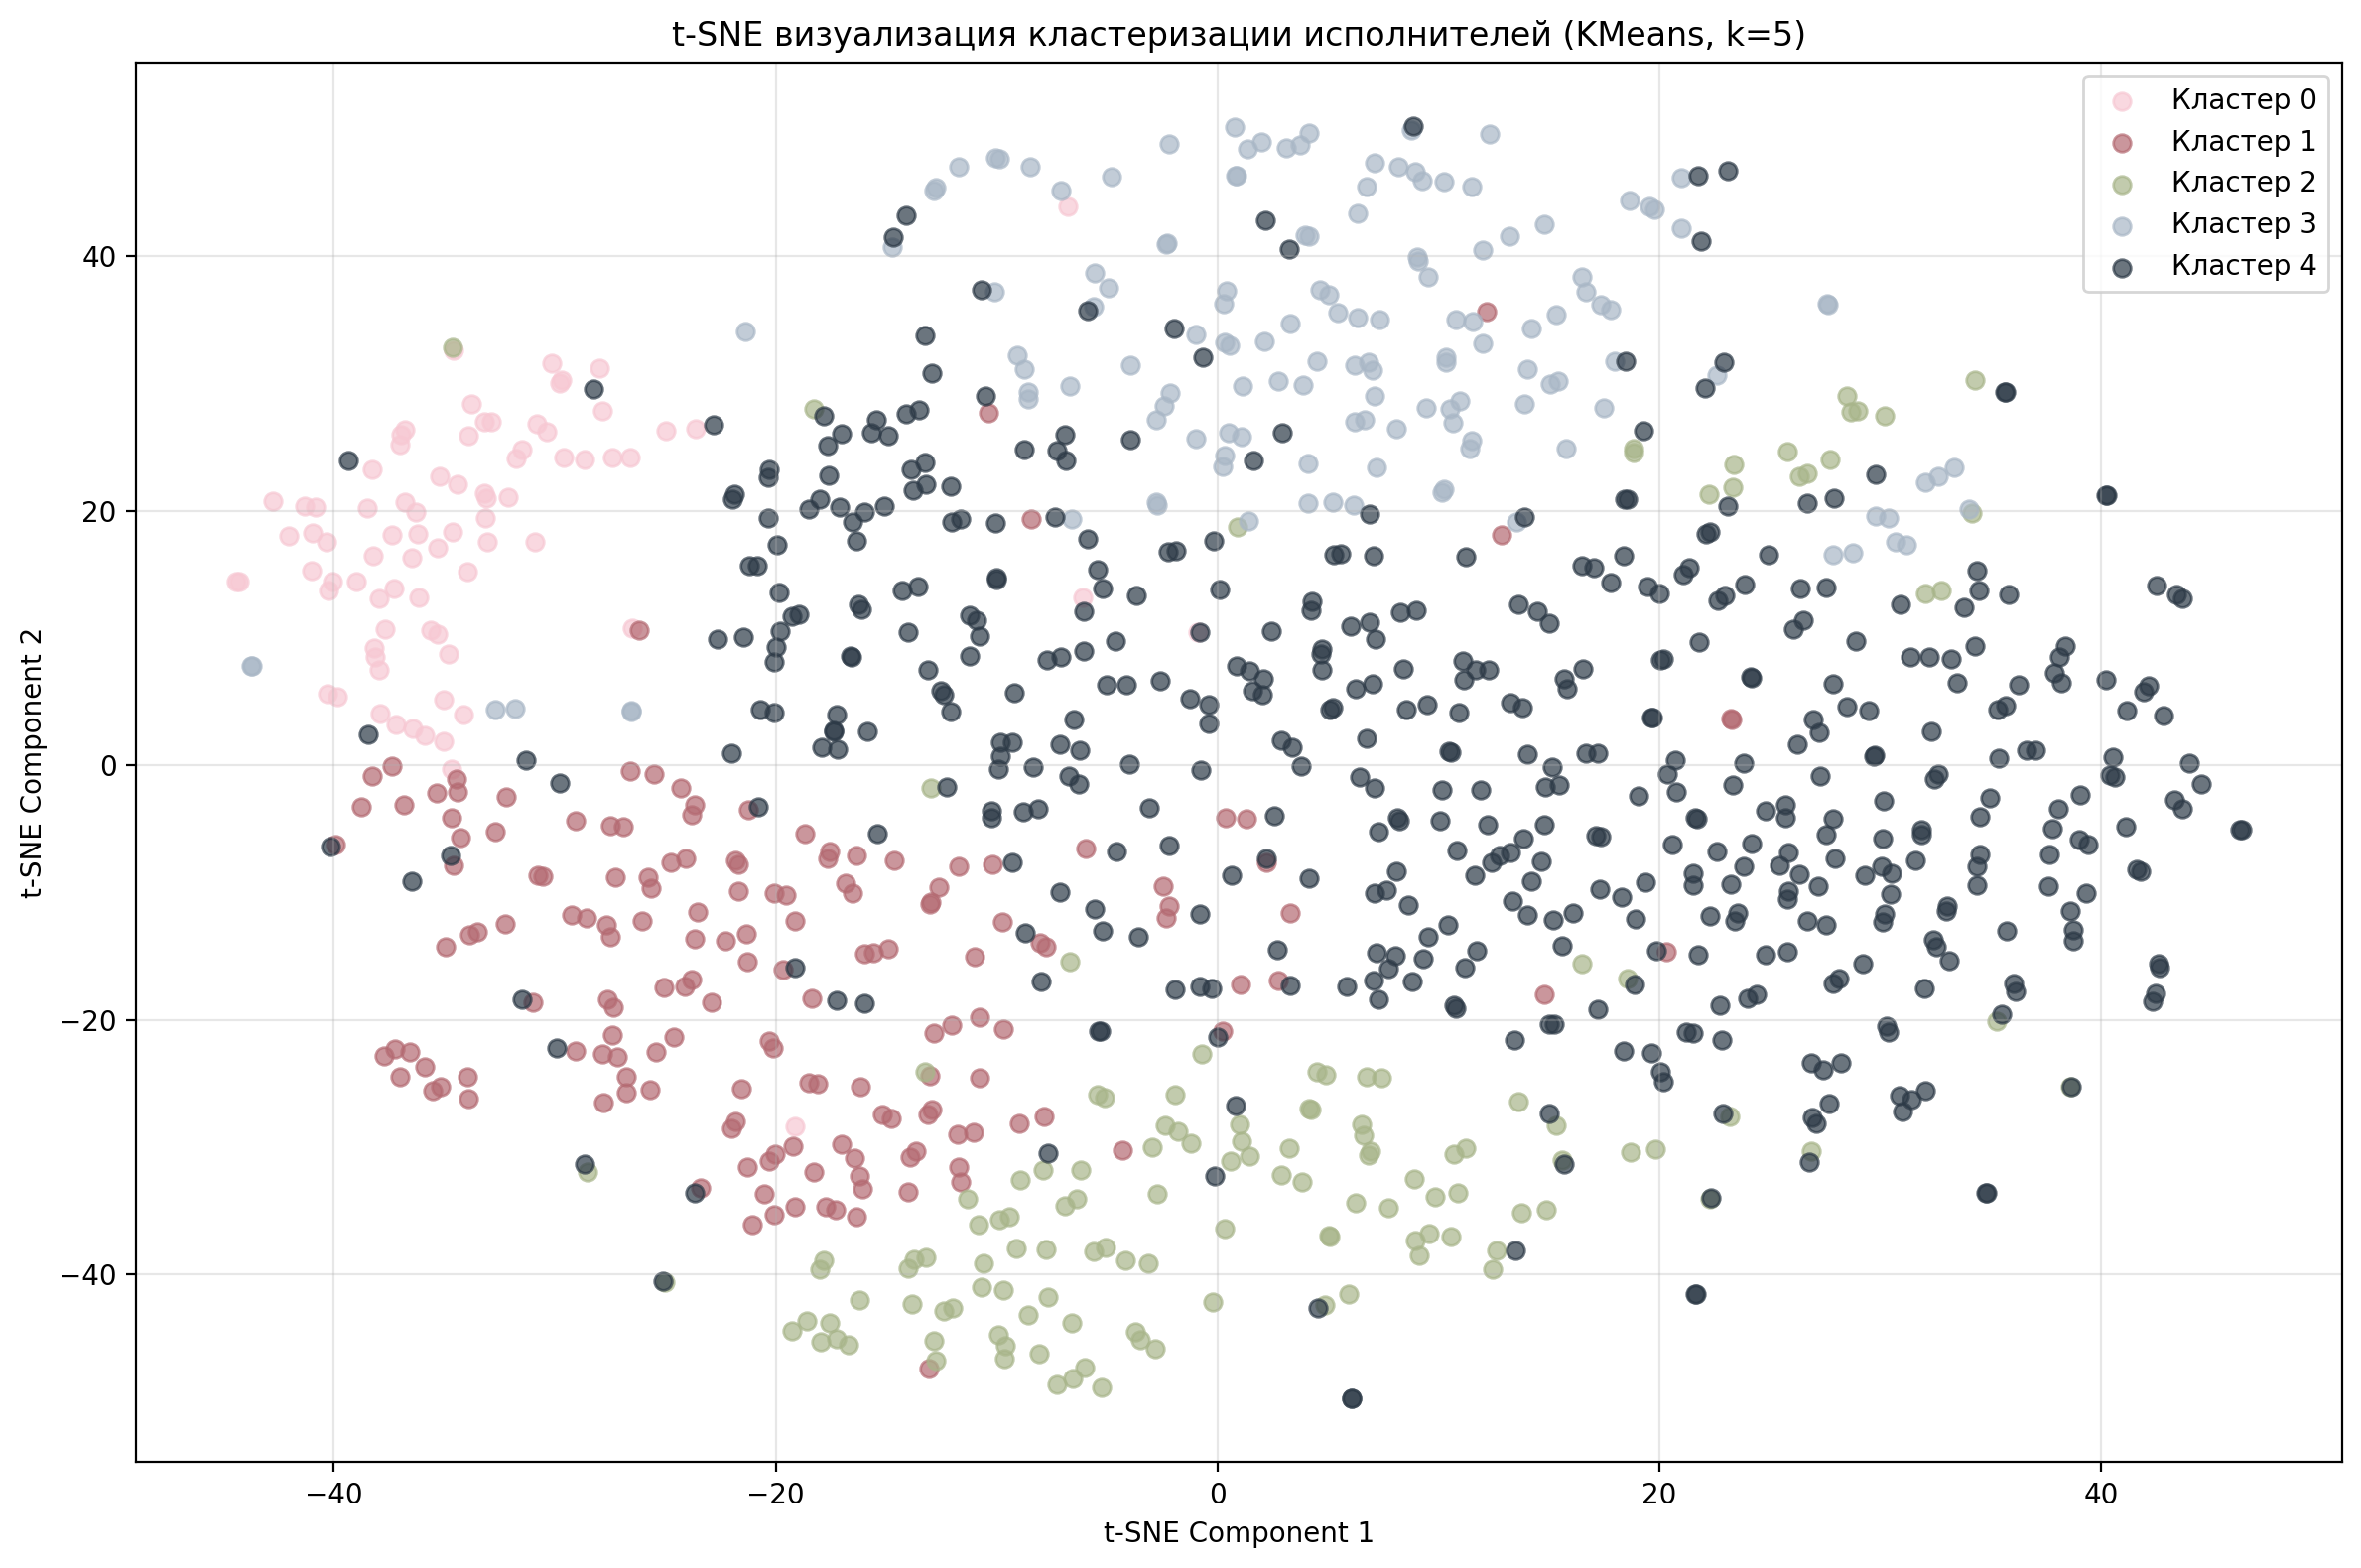

In [ ]:
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2,
            perplexity=30,
            random_state=42,
            n_iter=1000)

tsne_ratings_transpose_norm = tsne.fit_transform(ratings_transpose_norm)

colors = ['#f7c8d3', '#b46a72', '#a8b58a', '#a9b7c6', '#2d3a47']

plt.figure(figsize=(12, 8), dpi = 200)
for cluster in range(5):
    mask = cluster == modelka.labels_
    plt.scatter(tsne_ratings_transpose_norm[mask, 0], tsne_ratings_transpose_norm[mask, 1], c=colors[cluster], label=f'Кластер {cluster}',
                alpha=0.7, s=40)
artists_to_label = [
    'the beatles', 'radiohead', 'kanye west', 'nas',
    'coldplay', 'blink-182', 'pink fluid', 'jay-z']

plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.title('t-SNE визуализация кластеризации исполнителей (KMeans, k=5)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Задание 7 (1 балл) Подбор гиперпараметров

Подберите оптимальное количество кластеров (максимум 100 кластеров) с использованием индекса Силуэта. Зафиксируйте `random_state=42`

In [ ]:
from sklearn.metrics import silhouette_score
clusters = [3, 5, 7, 9, 12, 15, 20, 15, 30, 50, 65, 80, 100]

best_num_clusters = 0
best_score = 0
for num in clusters:
    kmeans = KMeans(n_clusters=num, random_state=42)
    kmeans.fit(ratings_transpose_norm)
    cluster_labels = kmeans.labels_
    score = silhouette_score(ratings_transpose_norm, cluster_labels)
    if best_score < score:
        best_score = score
        best_num_clusters = num


In [ ]:
print(f'best_score {best_score}')
print(f'best_num_clusters {best_num_clusters}')

best_score 0.01316849326894327
best_num_clusters 100


Выведите исполнителей, ближайших с центроидам (аналогично заданию 5). Как соотносятся результаты? Остался ли смысл кластеров прежним? Расскажите про смысл 1-2 интересных кластеров, если он изменился и кластеров слишком много, чтобы рассказать про все.

In [ ]:
Kmeans = KMeans(n_clusters=num, random_state=42)
Kmeans.fit(ratings_transpose_norm)

KMeans(n_clusters=100, random_state=42)

In [ ]:
cluster_labels = Kmeans.labels_
centroids = Kmeans.cluster_centers_

for cluster in range(100):
    print(f"\nКластер {cluster}:")
    distances = []
    for i, artist in enumerate(ratings_transpose_norm):
        dist = cosine(centroids[cluster], artist)
        distances.append((ratings_transpose.index[i], dist))

    distances.sort(key=lambda x: x[1])
    for artist, dist in distances[:10]:
        print(f"  {artist}: {dist:.4f}")


Кластер 0:
  dr. dre: 0.4512
  the faint: 0.5231
  violent femmes: 0.5418
  margot and the nuclear so and sos: 0.5424
  owen: 0.5523
  the bloodhound gang: 0.5694
  cursive: 0.8348
  van hallen: 0.8534
  bright eyes: 0.8848
  ironand wine: 0.9105

Кластер 1:
  john mayer: 0.4701
  matt nathanson: 0.4956
  gavin degraw: 0.5621
  jason mraz: 0.5765
  ray lamontagne: 0.5923
  joshua radin: 0.5977
  sara bareilles: 0.6117
  augustana: 0.6195
  maroon5: 0.6517
  o.a.r.: 0.7123

Кластер 2:
  white stripes: 0.4748
  the raconteurs: 0.5900
  beck: 0.6035
  spoon: 0.6107
  the strokes: 0.6370
  cake: 0.6600
  the flaming lips: 0.6625
  black rebel motorcycle club: 0.6721
  gorillaz: 0.6752
  the black keys: 0.6799

Кластер 3:
  fugazi: 0.4485
  jawbreaker: 0.4945
  capn jazz: 0.5794
  sleater-kinney: 0.5804
  les savy fav: 0.5990
  bad brains: 0.6006
  propagandhi: 0.6065
  gogol bordello: 0.6654
  black flag: 0.7451
  descendents: 0.8026

Кластер 4:
  ryan adams: 0.5104
  band of horses: 0.52

**Ответ:** # -- YOUR ANSWER HERE --

Сделайте t-SNE визуализацию полученной кластеризации.

/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(
/tmp/ipykernel_1444/2332764139.py:14: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(tsne_ratings_transpose_norm[mask, 0], tsne_ratings_transpose_norm[mask, 1], c=color, label=f'Кластер {cluster}',


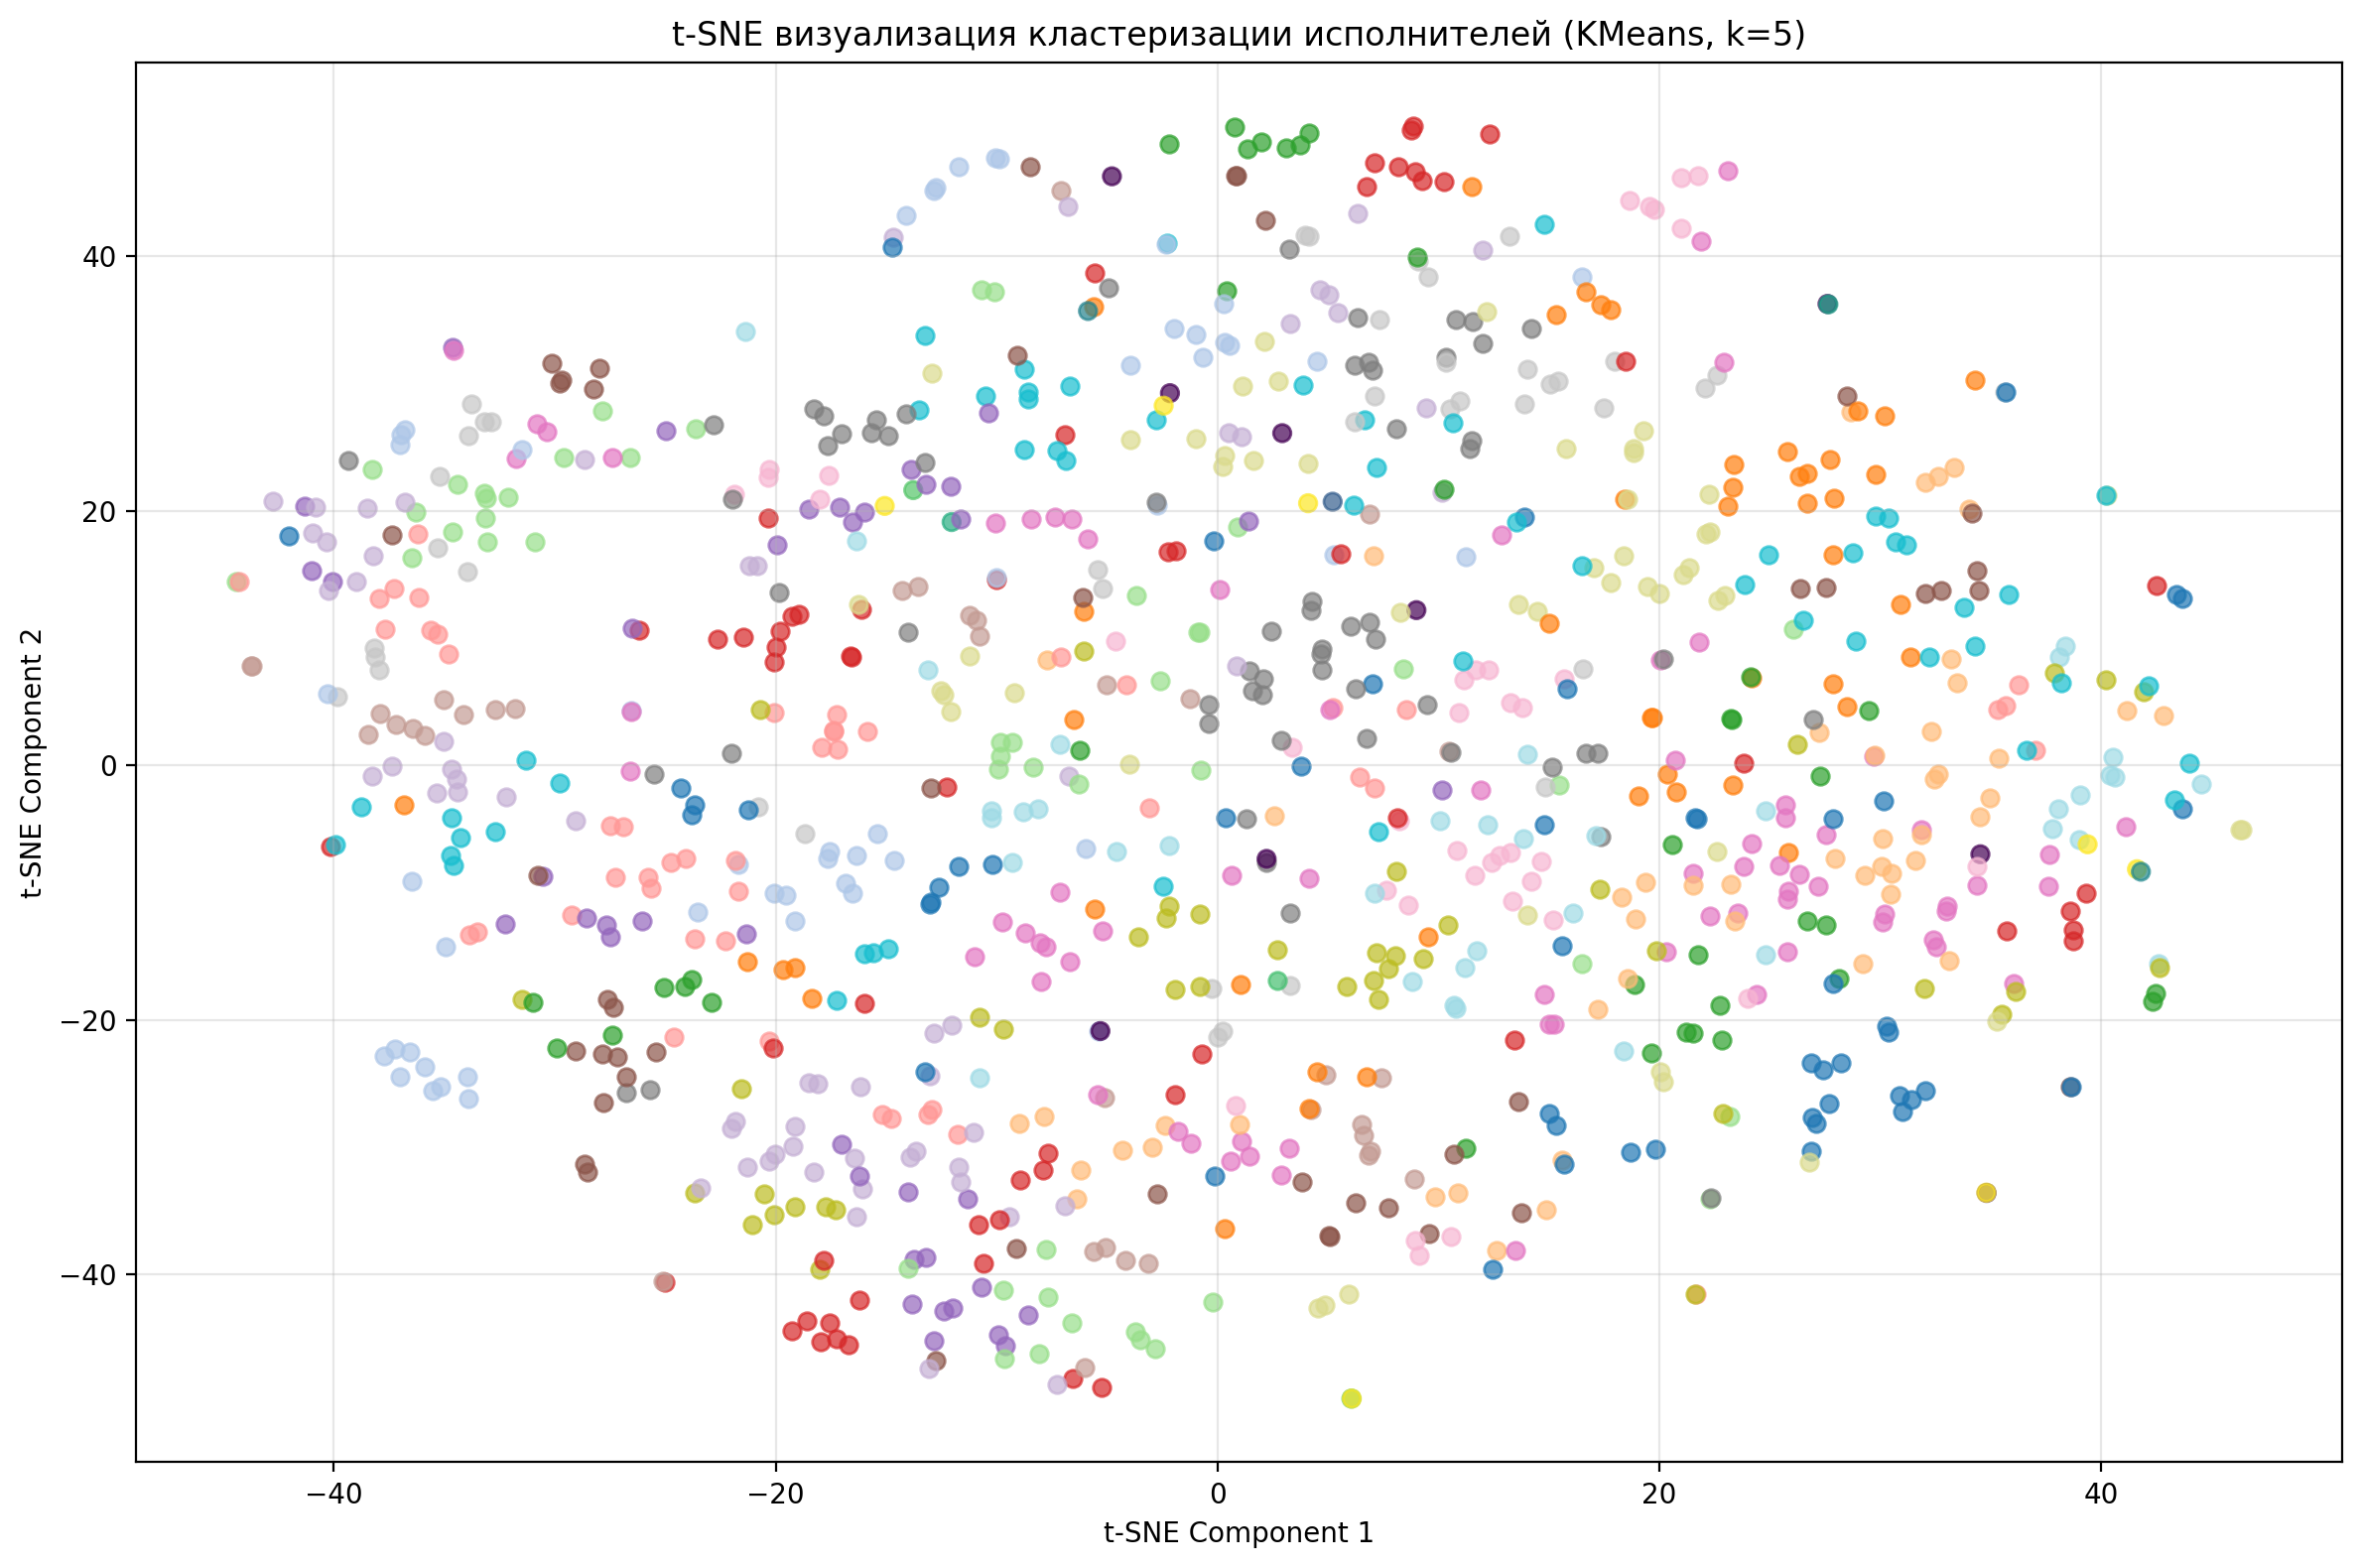

In [ ]:
tsne = TSNE(n_components=2,
            perplexity=30,
            random_state=42,
            n_iter=1000)

tsne_ratings_transpose_norm = tsne.fit_transform(ratings_transpose_norm)

cmap = plt.cm.tab20

plt.figure(figsize=(12, 8), dpi = 200)
for cluster in range(100):
    mask = cluster == Kmeans.labels_
    color = cmap(cluster % 20)
    plt.scatter(tsne_ratings_transpose_norm[mask, 0], tsne_ratings_transpose_norm[mask, 1], c=color, label=f'Кластер {cluster}',
                alpha=0.7, s=40)
artists_to_label = [
    'the beatles', 'radiohead', 'kanye west', 'nas',
    'coldplay', 'blink-182', 'pink fluid', 'jay-z']

plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.title('t-SNE визуализация кластеризации исполнителей (KMeans, k=5)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Если кластеров получилось слишком много и визуально цвета плохо отличаются, покрасьте только какой-нибудь интересный кластер из задания выше (`c = (labels == i)`). Хорошо ли этот кластер отражается в визуализации?

In [ ]:
# -- YOUR CODE HERE --

**Ответ:** # -- YOUR ANSWER HERE --